# Water Potability — Exploratory Data Analysis and Preprocessing
**Part 2 | Dataset:** `water_potability.csv`  
**Part 1 goals:** classification of `Potability`; regression of `ph`; clustering by chemical measurements.

Run cells from top to bottom. Keep the CSV in the same folder as this notebook (or edit `DATA_PATH`). All modeling preprocessing is fitted on training data only to prevent leakage. This notebook prepares datasets; model training is outside this assignment.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

sns.set_theme(style="whitegrid")
DATA_PATH = Path("water_potability.csv")
df = pd.read_csv(DATA_PATH)
features = df.drop(columns="Potability").columns.tolist()
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


## 1. Dataset structure, missingness, and summary statistics

In [2]:
print("Dimensions:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Missing values and percentages:")
display(pd.DataFrame({"Missing":df.isna().sum(), "Percent":(100*df.isna().mean()).round(2)}))
print("Target distribution:")
display(df["Potability"].value_counts().rename(index={0:"Not potable",1:"Potable"}))
display(df.describe().T.round(2))

Dimensions: (3276, 10)
Duplicate rows: 0
Missing values and percentages:


,Missing,Percent
ph,491,14.99
Hardness,0,0.00
Solids,0,0.00
Chloramines,0,0.00
Sulfate,781,23.84
Conductivity,0,0.00
Organic_carbon,0,0.00
Trihalomethanes,162,4.95
Turbidity,0,0.00
Potability,0,0.00


Target distribution:


Potability
Not potable    1998
Potable        1278
Name: count, dtype: int64

,count,mean,std,min,25%,50%,75%,max
ph,2785.0,7.08,1.59,0.00,6.09,7.04,8.06,14.00
Hardness,3276.0,196.37,32.88,47.43,176.85,196.97,216.67,323.12
Solids,3276.0,22014.09,8768.57,320.94,15666.69,20927.83,27332.76,61227.20
Chloramines,3276.0,7.12,1.58,0.35,6.13,7.13,8.11,13.13
Sulfate,2495.0,333.78,41.42,129.00,307.70,333.07,359.95,481.03
Conductivity,3276.0,426.21,80.82,181.48,365.73,421.88,481.79,753.34
Organic_carbon,3276.0,14.28,3.31,2.20,12.07,14.22,16.56,28.30
Trihalomethanes,3114.0,66.40,16.18,0.74,55.84,66.62,77.34,124.00
Turbidity,3276.0,3.97,0.78,1.45,3.44,3.96,4.50,6.74
Potability,3276.0,0.39,0.49,0.00,0.00,0.00,1.00,1.00


**Interpretation:** `ph`, `Sulfate`, and `Trihalomethanes` have missing values. The target is imbalanced (more non-potable than potable observations). The numeric features have different measurement scales, so distance-based methods and neural networks need scaling.

## 2. Univariate analysis — distributions and outliers

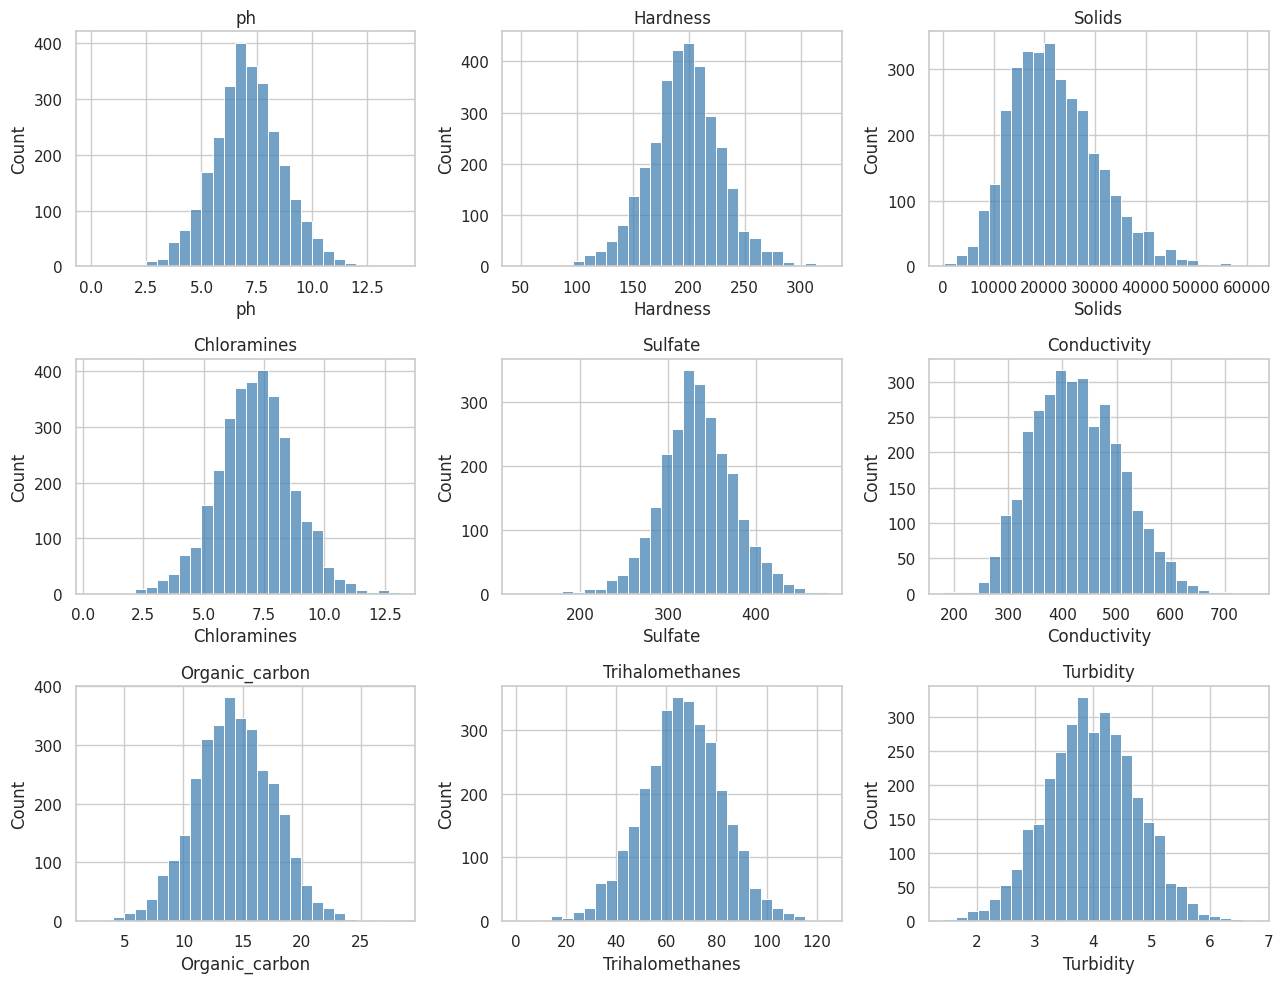

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, column in zip(axes.flat, features):
    sns.histplot(df[column].dropna(), bins=28, ax=ax, color="steelblue")
    ax.set_title(column)
plt.tight_layout(); plt.show()

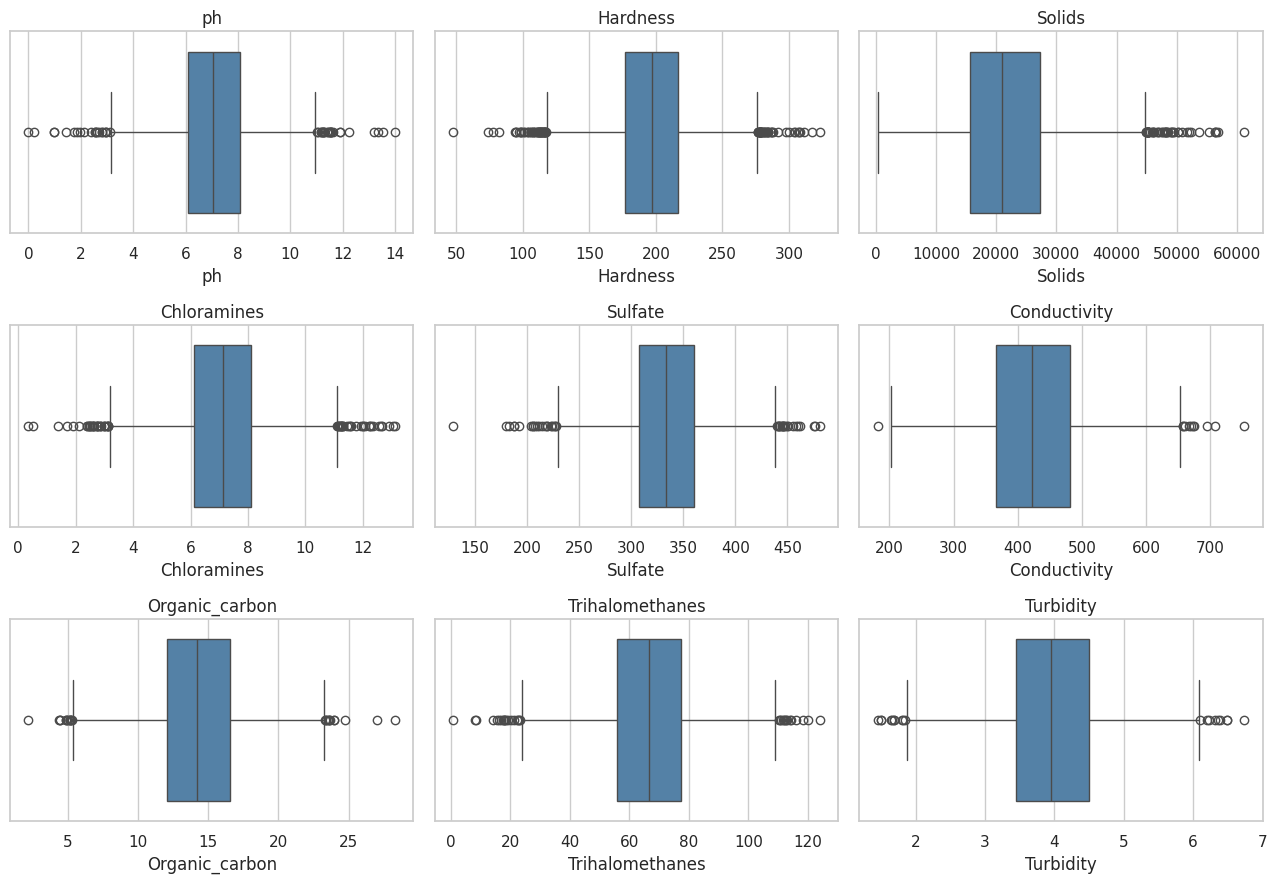

ph                 46
Hardness           83
Solids             47
Chloramines        61
Sulfate            41
Conductivity       11
Organic_carbon     25
Trihalomethanes    33
Turbidity          19
Name: IQR-flagged values, dtype: int64

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, column in zip(axes.flat, features):
    sns.boxplot(x=df[column], ax=ax, color="steelblue")
    ax.set_title(column)
plt.tight_layout(); plt.show()
# 1.5 x IQR rule: counts are indicators for review, not automatic deletions.
outlier_counts = {}
for column in features:
    q1, q3 = df[column].quantile([.25, .75]); iqr = q3 - q1
    outlier_counts[column] = int(((df[column] < q1-1.5*iqr) | (df[column] > q3+1.5*iqr)).sum())
display(pd.Series(outlier_counts, name="IQR-flagged values"))

**Outlier decision:** Retain flagged observations rather than deleting them automatically: extreme chemical readings might contain important water-safety information. If strong skew/outliers hurt later models, compare robust transforms or capping fitted to training data only; investigate impossible measurements separately.

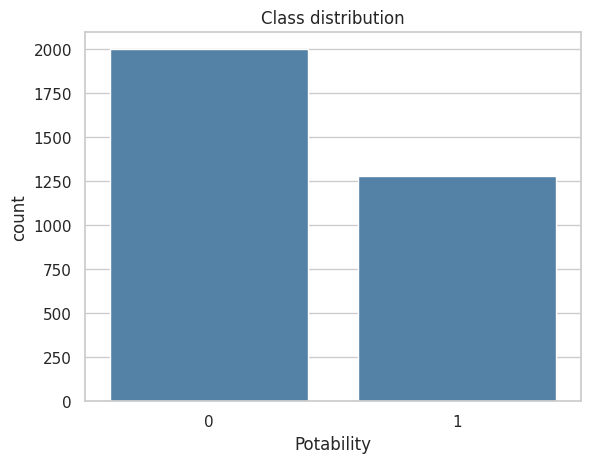

In [5]:
sns.countplot(data=df, x="Potability", color="steelblue")
plt.title("Class distribution"); plt.show()

## 3. Bivariate/multivariate analysis

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
ph,1.000,0.082,-0.089,-0.034,0.018,0.019,0.044,0.003,-0.039,-0.004
Hardness,0.082,1.000,-0.047,-0.030,-0.107,-0.024,0.004,-0.013,-0.014,-0.014
Solids,-0.089,-0.047,1.000,-0.070,-0.172,0.014,0.010,-0.009,0.020,0.034
Chloramines,-0.034,-0.030,-0.070,1.000,0.027,-0.020,-0.013,0.017,0.002,0.024
Sulfate,0.018,-0.107,-0.172,0.027,1.000,-0.016,0.031,-0.030,-0.011,-0.024
Conductivity,0.019,-0.024,0.014,-0.020,-0.016,1.000,0.021,0.001,0.006,-0.008
Organic_carbon,0.044,0.004,0.010,-0.013,0.031,0.021,1.000,-0.013,-0.027,-0.030
Trihalomethanes,0.003,-0.013,-0.009,0.017,-0.030,0.001,-0.013,1.000,-0.022,0.007
Turbidity,-0.039,-0.014,0.020,0.002,-0.011,0.006,-0.027,-0.022,1.000,0.002
Potability,-0.004,-0.014,0.034,0.024,-0.024,-0.008,-0.030,0.007,0.002,1.000


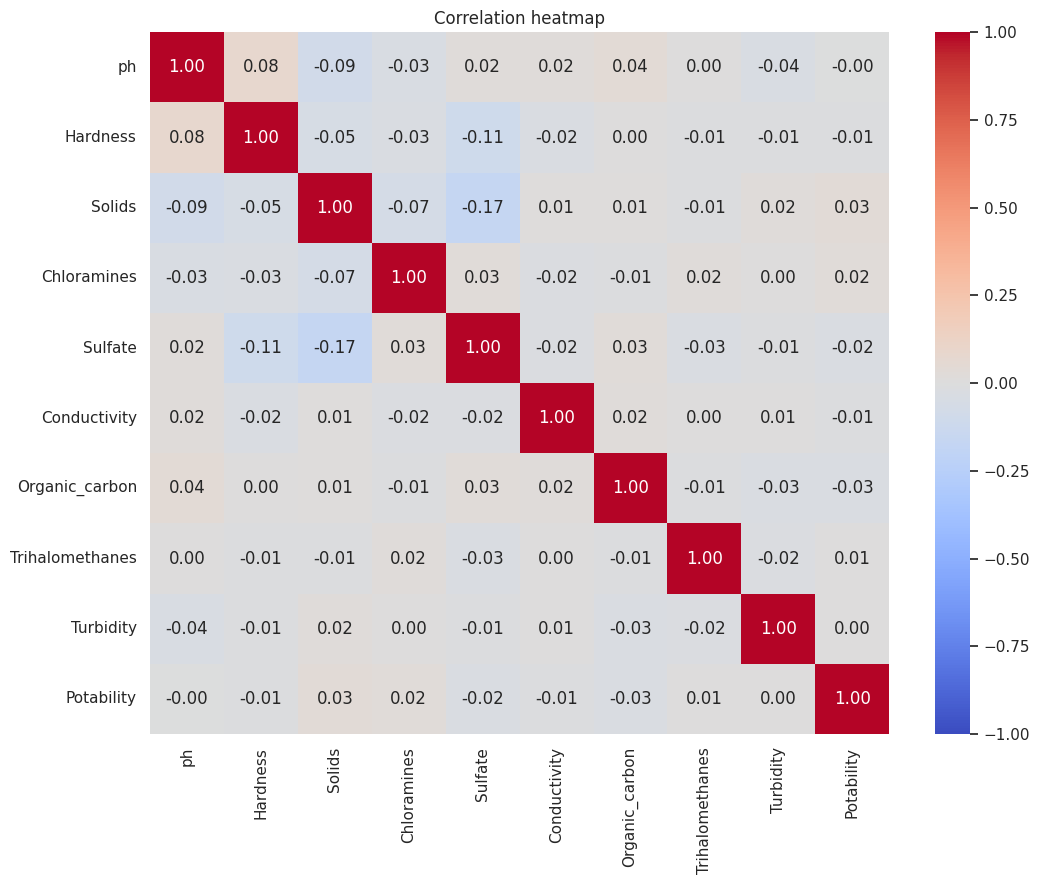

In [6]:
corr = df.corr(numeric_only=True)
display(corr.round(3))
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heatmap"); plt.tight_layout(); plt.show()

**Interpretation:** Linear associations are generally weak; that does not rule out nonlinear relationships. Correlation alone cannot determine whether water is safe. The heatmap also reveals feature–target relationships but should not be treated as proof of causation.

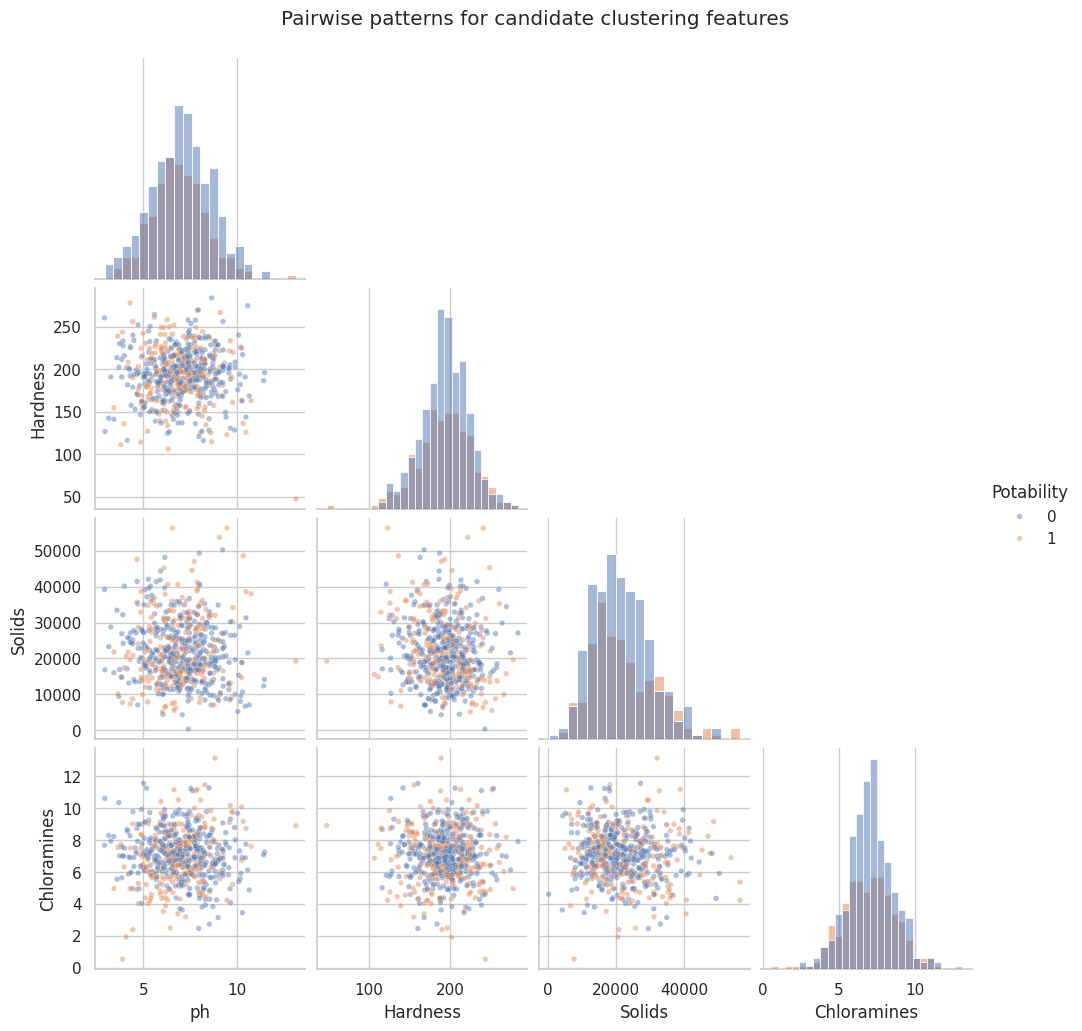

In [7]:
# Use a fixed random sample to keep the pair plot readable and quick.
cluster_view_cols = ["ph", "Hardness", "Solids", "Chloramines"]
pair_df = df[cluster_view_cols + ["Potability"]].dropna().sample(n=600, random_state=42)
g = sns.pairplot(pair_df, vars=cluster_view_cols, hue="Potability",
                 diag_kind="hist", corner=True, plot_kws={"alpha": .45, "s": 16})
g.fig.suptitle("Pairwise patterns for candidate clustering features", y=1.03)
plt.show()

## 4. Classification preprocessing — predict potability

All predictors are numerical; there are **no categorical predictors requiring one-hot encoding**. `Potability` is already encoded as 0/1. We keep all chemical features, impute numeric missing values with the **training-set median**, and standardize using **training-set mean/SD**. Stratification preserves target proportions. We do not use `Potability` to fit transformations.

In [8]:
X = df[features].copy()
y = df["Potability"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)
classification_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
X_train_ready = classification_preprocessor.fit_transform(X_train)
X_test_ready = classification_preprocessor.transform(X_test)
print("Classification train/test shapes:", X_train_ready.shape, X_test_ready.shape)
print("Remaining NaNs:", np.isnan(X_train_ready).sum(), np.isnan(X_test_ready).sum())

Classification train/test shapes: (2620, 9) (656, 9)
Remaining NaNs: 0 0


## 5. Regression preprocessing — predict pH

Rows with unknown pH cannot supply regression labels, so exclude them **only for this task**. Do not impute the target pH. All other chemical measurements are predictors; exclude `Potability` to avoid relying on a downstream safety label. Median-impute and standardize predictors from regression training data alone.

In [9]:
reg_df = df.dropna(subset=["ph"]).copy()
reg_features = [col for col in features if col != "ph"]
X_reg = reg_df[reg_features]; y_reg = reg_df["ph"]
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=.20, random_state=42)
regression_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
X_reg_train_ready = regression_preprocessor.fit_transform(X_reg_train)
X_reg_test_ready = regression_preprocessor.transform(X_reg_test)
print("Regression train/test shapes:", X_reg_train_ready.shape, X_reg_test_ready.shape)

Regression train/test shapes: (2228, 8) (557, 8)


## 6. Clustering preprocessing and optional PCA

Clustering should be unsupervised: **exclude `Potability`**. Impute and scale chemical features before K-means because Euclidean distance depends on feature magnitude. PCA with two components is a visualization aid, not a requirement; compare clustering on all standardized features with PCA-reduced features later.

PCA variance explained: [0.133 0.126]


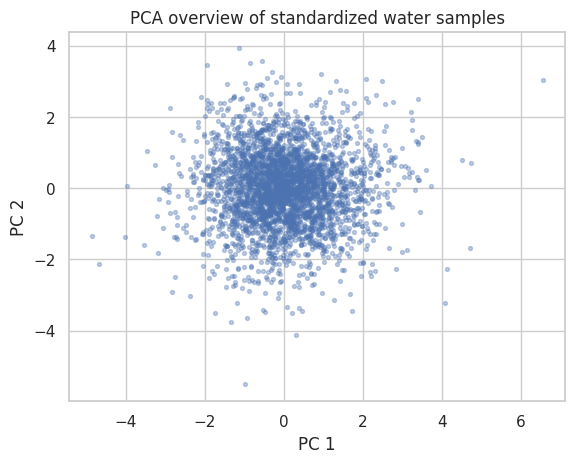

In [10]:
cluster_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
# Exploratory clustering only: fit on all records (no held-out performance claims).
X_cluster = cluster_preprocessor.fit_transform(df[features])
pca = PCA(n_components=2, random_state=42)
cluster_2d = pca.fit_transform(X_cluster)
print("PCA variance explained:", pca.explained_variance_ratio_.round(3))
plt.scatter(cluster_2d[:,0], cluster_2d[:,1], s=8, alpha=.35)
plt.xlabel("PC 1"); plt.ylabel("PC 2"); plt.title("PCA overview of standardized water samples"); plt.show()

## 7. Checks and decisions

In [11]:
# Verify prepared matrices are numeric, finite, and appropriately centered.
for label, matrix in [("classification train", X_train_ready),
                      ("classification test", X_test_ready),
                      ("regression train", X_reg_train_ready),
                      ("clustering", X_cluster)]:
    print(label, matrix.shape, "finite:", np.isfinite(matrix).all())
print("Classification training means:", np.round(X_train_ready.mean(axis=0), 3))

classification train (2620, 9) finite: True
classification test (656, 9) finite: True
regression train (2228, 8) finite: True
clustering (3276, 9) finite: True
Classification training means: [ 0. -0.  0.  0.  0.  0. -0. -0. -0.]


### Preprocessing summary
- **Missing values:** Median imputation for predictor variables; pH-missing rows excluded only from supervised pH regression.
- **Outliers:** Identified by IQR, retained pending domain review; do not silently discard potentially meaningful contamination extremes.
- **Scaling:** `StandardScaler` supports neural networks, k-NN, SVM, PCA and K-means; fit exclusively on training split for supervised tasks.
- **Categorical encoding/bins:** No categorical predictors exist and the binary potability label is already encoded; no unnecessary bins were created, preserving information.
- **Feature engineering:** Optional two-component PCA only for exploratory visualization. Avoid imposing PCA on the final neural network without validation.
- **Bias/leakage:** Preserve class proportions, check metrics by subgroup if group identifiers become available, validate imputation by comparing distributions, and evaluate on untouched test data. `Potability` labels are not regulatory proof that any water source is safe.

**Note:** A random row split may overstate generalization if records share a water source/time; no source/time identifiers are provided to enforce group-based splitting.